# Partie A — Cavité entraînée à $Re = 100$ : solveur de référence vérifié

Plan du notebook (cf. `PLAN.md`, étapes 1 à 3) :

1. **Vérification du solveur de Poisson** (gradient conjugué sans matrice, `cavity/common.py`)
   sur des solutions connues, en Dirichlet (pour $\psi$) et en Neumann (pour $p$).
2. M1 (projection) à $Re = 100$ pour $N = 32, 64, 128$ : profils vs Ghia, justification de la grille,
   $K(t)$, $P(t)$, $P$ stationnaire en fonction de $\ln N$.
3. M2 ($\psi$–$\omega$, Thom) et comparaison M1 / M2 / Ghia.

Adimensionnement : $L = U = \rho = 1$, $\nu = 1/Re$. Grille colocalisée aux nœuds, $h = 1/N$.

In [1]:
# Imports et chemins : le notebook est dans notebooks/, le paquet cavity/ est à la racine du projet
import os
# Contournement d'un défaut de l'environnement CFD sur cette machine : la couche de threads OpenMP
# de MKL fait planter toute algèbre linéaire numpy (np.linalg, donc aussi matplotlib) ; on force
# MKL en séquentiel. Doit être fixé AVANT le premier import de numpy. Sans effet sur nos calculs.
os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"
RES = ROOT / "results"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

from cavity.common import solve_poisson

GRIDS_POISSON = (16, 32, 64)       # grilles demandées pour la vérification du Poisson
TOL_CG = 1e-10                     # résidu relatif : bien sous l'erreur de discrétisation attendue


def observed_slopes(n_list, errors):
    # Pente observée entre deux grilles successives (h divisé par 2) : log2(e_N / e_2N),
    # et pente globale par régression linéaire de log(e) en fonction de log(h) (workshop 9).
    # Régression écrite à la main : pente des moindres carrés = cov(log h, log e) / var(log h).
    e = np.asarray(errors, dtype=float)
    local = np.log2(e[:-1] / e[1:])
    log_h = np.log(1.0 / np.asarray(n_list, dtype=float))
    log_e = np.log(e)
    dh = log_h - log_h.mean()
    global_fit = np.sum(dh * (log_e - log_e.mean())) / np.sum(dh * dh)
    return local, global_fit

## 1. Vérification du solveur de Poisson

### 1.a Dirichlet : $\phi = (x^2-1)(y^2-1)$ (workshop 11.1)

**Ce qu'on fait.** On résout $\Delta\phi = f = 2(x^2 + y^2 - 2)$ sur $[-1, 1]^2$ avec $\phi = 0$ au bord
(problème du workshop 11.1, donc sur $[-1,1]^2$ et non sur le carré unité : c'est là que $\phi$ s'annule au bord ;
le pas vaut $h = 2/N$). Départ du gradient conjugué de zéro, tolérance $10^{-10}$ sur le résidu relatif.

**Ce qu'on attend.** Attention : l'erreur de troncature du laplacien 5 points est
$\tfrac{h^2}{12}(\partial^4_x\phi + \partial^4_y\phi) + O(h^4)$ (cours §2.3), et ici $\phi$ est de degré 2 en
chaque variable : **le schéma est exact**. L'erreur ne mesure donc que l'arrêt du gradient conjugué
($\sim 10^{-12}$) ; il n'y a **pas de pente 2** à observer sur ce cas. Il sert à vérifier que le solveur
(stencil, conditions aux limites, gradient conjugué) est juste. Nombre d'itérations attendu : $O(N)$
(complexité $O(n^{3/2})$ avec $n = N^2$ inconnues, cours §4.8).

In [2]:
rows_dir = []
for n in GRIDS_POISSON:
    h = 2.0 / n
    x = np.linspace(-1.0, 1.0, n + 1)
    X, Y = np.meshgrid(x, x, indexing="ij")          # [i, j] <-> (x, y)
    phi_exact = (X**2 - 1.0) * (Y**2 - 1.0)
    f = 2.0 * (X**2 + Y**2 - 2.0)
    phi, n_iter = solve_poisson(f[1:-1, 1:-1], h, "dirichlet", tol=TOL_CG)
    err = np.abs(phi - phi_exact).max()
    rows_dir.append((n, err, n_iter))
    print(f"N = {n:3d}   max|phi - phi_exact| = {err:.3e}   itérations GC = {n_iter}")

N =  16   max|phi - phi_exact| = 1.594e-12   itérations GC = 28
N =  32   max|phi - phi_exact| = 1.108e-12   itérations GC = 59
N =  64   max|phi - phi_exact| = 9.919e-13   itérations GC = 120


**Lecture.** Erreur $\sim 10^{-12}$ sur les trois grilles, indépendante de $N$ : c'est la précision d'arrêt du
gradient conjugué, comme prévu pour un schéma exact sur ce polynôme. Le nombre d'itérations double
quand $N$ double : $O(N)$, conforme au cours (§4.8).

### 1.b Complément Dirichlet : $\phi = \sin(\pi x)\sin(\pi y)$ sur $[0, 1]^2$

**Ce qu'on fait.** Le cas 1.a ne peut pas donner d'ordre. On ajoute donc un cas dont la dérivée quatrième
n'est pas nulle : $\Delta\phi = -2\pi^2\phi$, $\phi = 0$ sur les parois du carré unité (notre domaine).

**Ce qu'on attend.** Pente $\approx 2$. Remarque : $\sin(\pi x_i)\sin(\pi y_j)$ est un **vecteur propre** du laplacien
discret en Dirichlet, donc le gradient conjugué converge en **1 itération** (le résidu initial est colinéaire à
un vecteur propre) : ce cas ne sert pas à compter les itérations, c'est le cas 1.a qui le fait.

In [3]:
rows_sin = []
for n in GRIDS_POISSON:
    h = 1.0 / n
    x = np.linspace(0.0, 1.0, n + 1)
    X, Y = np.meshgrid(x, x, indexing="ij")
    phi_exact = np.sin(np.pi * X) * np.sin(np.pi * Y)
    phi, n_iter = solve_poisson((-2.0 * np.pi**2 * phi_exact)[1:-1, 1:-1], h, "dirichlet", tol=TOL_CG)
    err = np.abs(phi - phi_exact).max()
    rows_sin.append((n, err, n_iter))
    print(f"N = {n:3d}   max|phi - phi_exact| = {err:.3e}   itérations GC = {n_iter}")

local, glob = observed_slopes(GRIDS_POISSON, [r[1] for r in rows_sin])
print("pentes locales :", np.round(local, 3), "  pente globale :", round(glob, 3))

N =  16   max|phi - phi_exact| = 3.219e-03   itérations GC = 1
N =  32   max|phi - phi_exact| = 8.036e-04   itérations GC = 1
N =  64   max|phi - phi_exact| = 2.008e-04   itérations GC = 1
pentes locales : [2.002 2.001]   pente globale : 2.001


### 1.c Neumann : $\phi = \cos(\pi x)\cos(\pi y)$ sur $[0, 1]^2$

**Ce qu'on fait.** $\Delta\phi = -2\pi^2\phi$ avec $\partial\phi/\partial n = 0$ sur les quatre parois (vrai pour
cette $\phi$), exactement comme pour la pression de M1 : bord = voisin intérieur (Neumann décentrée
d'ordre 1, cours §4.2.2.2), moyenne du second membre retirée, $\phi$ à moyenne nulle à chaque itération.
La moyenne de $\phi_\text{exact}$ sur les nœuds intérieurs est nulle (symétrie), on peut donc comparer directement.
Erreur mesurée sur les nœuds intérieurs (les nœuds de bord sont une simple recopie).

**Ce qu'on attend.** On pourrait attendre une pente $\approx 2$ (ordre du laplacien), mais l'analyse avant calcul prévoit plutôt
**une pente $\approx 1$** : la règle $\phi_0 = \phi_1$ impose $\partial\phi/\partial n = 0$ **entre** les nœuds 0 et 1,
c'est-à-dire que le schéma résout (à l'ordre 2) le problème de Neumann sur le domaine décalé
$[h/2,\ 1-h/2]^2$. En 1D, la solution de $\phi'' = -\pi^2\cos(\pi x)$ avec $\phi'(h/2) = \phi'(1-h/2) = 0$ vaut
$\cos(\pi x) + \pi\sin(\pi h/2)\,x + c$ : l'écart à la vraie solution est une **pente linéaire en $x$**,
d'amplitude $\approx \tfrac{\pi^2}{2}h\,(x - \tfrac12)$, donc une erreur maximale $\approx \tfrac{\pi^2}{4}h \approx 2.5\,h$ en 1D.

In [4]:
rows_neu = []
profiles_neu = {}                     # erreur le long de y = 0.5 (pour la figure)
for n in GRIDS_POISSON:
    h = 1.0 / n
    x = np.linspace(0.0, 1.0, n + 1)
    X, Y = np.meshgrid(x, x, indexing="ij")
    phi_exact = np.cos(np.pi * X) * np.cos(np.pi * Y)
    phi, n_iter = solve_poisson((-2.0 * np.pi**2 * phi_exact)[1:-1, 1:-1], h, "neumann", tol=TOL_CG)
    error = phi - phi_exact
    err = np.abs(error[1:-1, 1:-1]).max()
    rows_neu.append((n, err, n_iter))
    profiles_neu[n] = (x, error[:, n // 4])          # coupe y = 0.25 (cos(pi y) = 0 en y = 0.5)
    print(f"N = {n:3d}   max|phi - phi_exact| (intérieur) = {err:.3e}   err/h = {err / h:.2f}"
          f"   itérations GC = {n_iter}   moyenne(phi) = {phi[1:-1, 1:-1].mean():+.1e}")

local, glob = observed_slopes(GRIDS_POISSON, [r[1] for r in rows_neu])
print("pentes locales :", np.round(local, 3), "  pente globale :", round(glob, 3))

N =  16   max|phi - phi_exact| (intérieur) = 1.423e-01   err/h = 2.28   itérations GC = 23   moyenne(phi) = -9.9e-19
N =  32   max|phi - phi_exact| (intérieur) = 8.055e-02   err/h = 2.58   itérations GC = 48   moyenne(phi) = +2.8e-18
N =  64   max|phi - phi_exact| (intérieur) = 4.265e-02   err/h = 2.73   itérations GC = 93   moyenne(phi) = -3.6e-18
pentes locales : [0.821 0.918]   pente globale : 0.869


**Figure** : erreur max en fonction de $h$ (log-log) pour Dirichlet ($\sin\sin$) et Neumann ($\cos\cos$), avec
les droites de pente 1 et 2 ; à droite, l'erreur Neumann le long de la coupe $y = 1/4$ divisée par $h$
(si l'analyse du domaine décalé est juste, les courbes se superposent : erreur $\propto h$, de forme régulière).

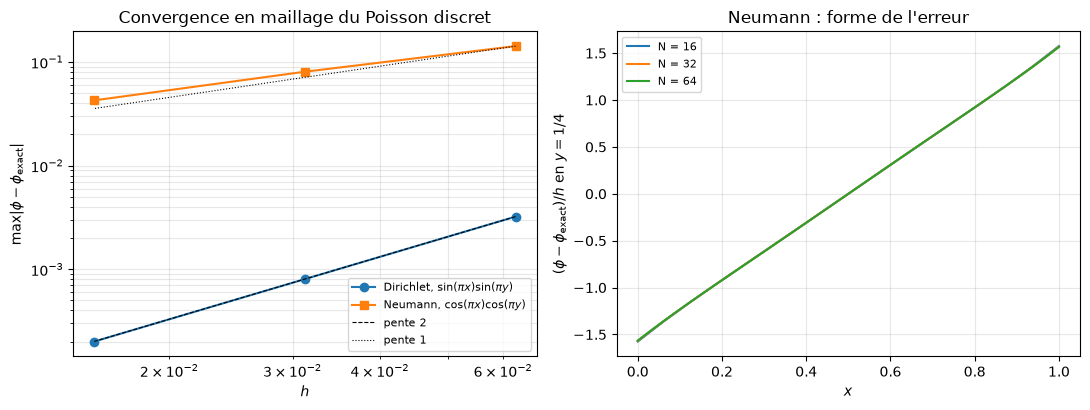

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
h_list = 1.0 / np.array(GRIDS_POISSON, dtype=float)
e_sin = np.array([r[1] for r in rows_sin])
e_neu = np.array([r[1] for r in rows_neu])
ax.loglog(h_list, e_sin, "o-", label=r"Dirichlet, $\sin(\pi x)\sin(\pi y)$")
ax.loglog(h_list, e_neu, "s-", label=r"Neumann, $\cos(\pi x)\cos(\pi y)$")
ax.loglog(h_list, e_sin[0] * (h_list / h_list[0])**2, "k--", lw=0.8, label="pente 2")
ax.loglog(h_list, e_neu[0] * (h_list / h_list[0])**1, "k:", lw=0.8, label="pente 1")
ax.set_xlabel("$h$")
ax.set_ylabel(r"$\max|\phi - \phi_\mathrm{exact}|$")
ax.set_title("Convergence en maillage du Poisson discret")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)

ax = axes[1]
for n, (x, err_line) in profiles_neu.items():
    ax.plot(x, err_line * n, label=f"N = {n}")     # erreur / h
ax.set_xlabel("$x$")
ax.set_ylabel(r"$(\phi - \phi_\mathrm{exact}) / h$ en $y = 1/4$")
ax.set_title("Neumann : forme de l'erreur")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(FIG / "A_poisson_convergence.png", dpi=150)
plt.show()

# Résultats numériques
table = np.array([[n, ed, it_d, es, it_s, en, it_n]
                  for (n, ed, it_d), (_, es, it_s), (_, en, it_n) in zip(rows_dir, rows_sin, rows_neu)])
np.savetxt(RES / "A_poisson_verification.csv", table, delimiter=",", fmt="%.6e",
           header="N,err_dirichlet_quadratique,iter_dirichlet_quadratique,err_dirichlet_sinsin,"
                  "iter_dirichlet_sinsin,err_neumann_coscos,iter_neumann_coscos")

**Interprétation.**

- **Dirichlet** : pente 2 sur $\sin\sin$, l'ordre attendu du laplacien 5 points ; avec le cas exact 1.a, le
  solveur Dirichlet (utilisé pour $\psi$ dans M2) est vérifié.
- **Neumann** : pente $\approx 1$ (0,82 puis 0,92, globale 0,87 : elle tend vers 1 quand $h$ diminue), et non 2.
  Ce n'est pas un défaut du gradient conjugué : la règle $\phi_0 = \phi_1$ (Neumann décentrée d'ordre 1,
  cours §4.2.2.2) revient à placer la paroi en $h/2$. Les courbes « erreur / $h$ » des trois grilles se
  superposent, ce qui confirme une erreur **globale** en $O(h)$, régulière et étalée sur tout le domaine
  (pas seulement la rangée de bord). Erreur max mesurée $\approx 2.3\,h$ à $2.7\,h$ ; l'estimation 1D donne
  $\approx 2.5\,h$, du même ordre (en 2D la correction n'est pas exactement la pente linéaire du cas 1D,
  on ne prétend donc qu'à l'ordre de grandeur).
- **Conséquence pour M1** : la pression de M1 sera au mieux d'ordre 1. Cela ne dit pas encore que les
  **vitesses** le seront : c'est ce que mesurera l'étude de grille de la Partie A (étape 2), puis la comparaison
  avec M2 (qui n'a pas de Neumann). Conformément au PLAN, on ne change rien tant que cette mesure n'est pas faite.
- **Itérations** : $O(N)$ pour les deux conditions aux limites (départ de zéro). En marche en temps, le départ
  à chaud depuis la pression du pas précédent devrait en réduire fortement le nombre.

## 2. M1 (projection) à $Re = 100$ : validation et justification de la grille

### 2.a Calculs

**Ce qu'on fait.** M1 (`cavity/projection.py`, cours §7.3.2 et workshop 15) : Euler explicite, advection
**centrée**, diffusion centrée, pression par gradient conjugué Neumann (tol $= 10^{-8}$, départ à chaud).
Départ du repos, couvercle $U_t = 1 - e^{-t}$. $\Delta t$ = limites de stabilité du cours (§5.3), marge 0.8.

**Critère d'arrêt** (`docs/adr/0003-pas-de-temps-et-arrets.md` §2), comme au Projet 1 (question b) : on surveille le
**résidu stationnaire** $R = (u^{n+1}-u^n)/\Delta t$ (composantes $u$ et $v$, nœuds intérieurs, norme L2). Avec Euler
explicite, $R$ est exactement le membre de droite discret ($-$advection $+\ \nu\Delta u - \nabla p$) : il mesure de combien le
champ viole les équations stationnaires, et ne dépend pas de $\Delta t$. Le fluide partant du repos, le résidu initial est
nul : la référence est prise à $t_\text{ref} = 10$ (rampe du couvercle terminée), et on s'arrête dès que
$\|R\| < \varepsilon\,\|R(t_\text{ref})\|$. La valeur de $\varepsilon$ est fixée par le test de 2.b.

Cas calculés (tous indépendants, donc lancés **en parallèle**, un processus par cas ; noyaux compilés par **Numba**) :
$N = 32, 64, 128$ pour $\varepsilon = 10^{-2}, 10^{-3}, 10^{-4}$. Résultats sauvegardés dans `results/` et relus si présents
(`RECOMPUTE = True` pour tout recalculer).

**Ce qu'on attend.**
- $\Delta t$ limité par l'advection (CFL) à $N = 32$ et par la diffusion (Fourier) à $N = 64, 128$ (croisement à $N = Re/2 = 50$).
- Le résidu décroît en $e^{-\lambda t}$ près du stationnaire : chaque décade de $\varepsilon$ ajoute la même durée $\ln 10/\lambda$.

In [6]:
from cavity.projection import run_projection

RE = 100
NU = 1.0 / RE
GRIDS = (32, 64, 128)
CG_TOL = 1e-8
T_REF = 10.0
EPS_CANDIDATES = (1e-2, 1e-3, 1e-4)
RECOMPUTE = False


def save_run(run, path):
    np.savez(path, **{key: np.asarray(val) for key, val in run.items()})


def load_run(path):
    data = np.load(path)
    return {key: (data[key].item() if data[key].ndim == 0 else data[key]) for key in data.files}


from cavity.psi_omega import run_psi_omega

RUNNERS = {"M1": run_projection, "M2": run_psi_omega}     # même signature pour les deux méthodes


def run_path(n, cg_tol, eps, method="M1"):
    return RES / f"A_{method}_N{n}_tol{cg_tol:.0e}_res{eps:.0e}.npz"


def compute_missing(cases, method="M1"):
    # Les calculs sont indépendants : on lance ceux qui manquent EN PARALLÈLE, un processus par cas
    # (chaque calcul n'utilise qu'un cœur ; la machine en a 32). Le temps total devient celui du cas
    # le plus long au lieu de la somme. Aucune modification du schéma numérique.
    from concurrent.futures import ProcessPoolExecutor
    missing = [c for c in cases if RECOMPUTE or not run_path(*c, method=method).exists()]
    if not missing:
        return
    os.environ["PYTHONPATH"] = str(ROOT)      # les processus fils doivent trouver le paquet cavity/
    with ProcessPoolExecutor(max_workers=len(missing)) as pool:
        futures = {c: pool.submit(RUNNERS[method], c[0], RE, "centered", cg_tol=c[1], residual_tol=c[2],
                                  t_ref=T_REF) for c in missing}
        for case, future in futures.items():
            save_run(future.result(), run_path(*case, method=method))
            print(f"calculé : {method}, N = {case[0]}, tol GC = {case[1]:.0e}, ε = {case[2]:.0e}")


def get_run(n, eps, cg_tol=CG_TOL, method="M1"):
    # Relit un calcul sauvegardé dans results/ (compute_missing l'a produit si besoin).
    return load_run(run_path(n, cg_tol, eps, method=method))


def active_limit(h, nu):
    # Quelle limite de stabilité fixe Δt (cf. cavity/common.time_step)
    limits = {"Fourier": h**2 / (4 * nu), "CFL": h / 2, "centré 2ν": 2 * nu}
    return min(limits, key=limits.get)


compute_missing([(n, CG_TOL, eps) for n in GRIDS for eps in EPS_CANDIDATES])

print(f"{'N':>4} {'dt':>9} {'limite':>9} | {'ε':>6} {'pas':>6} {'t_final':>7} {'calcul (s)':>10} "
      f"{'it. GC':>6} {'||R(t_ref)||':>12} {'arrêt':>8}")
for n in GRIDS:
    for eps in EPS_CANDIDATES:
        r = get_run(n, eps)
        stop = "critère" if r["converged"] else "t_max !"      # t_max atteint = signal d'alerte
        print(f"{n:4d} {r['dt']:9.3e} {active_limit(r['h'], NU):>9} | {eps:6.0e} {r['n_steps']:6d} "
              f"{r['t_final']:7.2f} {r['wall_time']:10.1f} {r['cg_iterations'].mean():6.1f} "
              f"{r['residual_ref']:12.3e} {stop:>8}")
print("Temps mesurés avec 9 calculs en parallèle (cœurs partagés : temps un peu pessimistes).")

   N        dt    limite |      ε    pas t_final calcul (s) it. GC ||R(t_ref)||    arrêt
  32 1.250e-02       CFL |  1e-02   1494   18.67        0.9   76.1    1.878e-02  critère
  32 1.250e-02       CFL |  1e-03   1839   22.99        0.9   64.7    1.878e-02  critère
  32 1.250e-02       CFL |  1e-04   2185   27.31        1.0   55.1    1.878e-02  critère
  64 4.883e-03   Fourier |  1e-02   3819   18.65        6.7  134.3    5.278e-02  critère
  64 4.883e-03   Fourier |  1e-03   4700   22.95        6.9  111.9    5.278e-02  critère
  64 4.883e-03   Fourier |  1e-04   5586   27.28        7.0   95.4    5.278e-02  critère
 128 1.221e-03   Fourier |  1e-02  15232   18.59      118.2  188.1    1.156e-01  critère
 128 1.221e-03   Fourier |  1e-03  18734   22.87      119.7  155.9    1.156e-01  critère
 128 1.221e-03   Fourier |  1e-04  22254   27.17      122.7  133.5    1.156e-01  critère
Temps mesurés avec 9 calculs en parallèle (cœurs partagés : temps un peu pessimistes).


**Lecture.**
- $\Delta t$ : CFL à $N = 32$, Fourier à $N = 64$ et $128$, comme prévu (croisement à $N = 50$).
- Tous les calculs s'arrêtent par le critère (aucun n'atteint $t_\max$) : l'écoulement devient bien stationnaire.
- **Pour un même $\varepsilon$, les trois grilles s'arrêtent au même instant** ($t \approx 18.6$ pour $\varepsilon = 10^{-2}$), alors que
  leurs $\Delta t$ diffèrent d'un facteur 10 : le critère sur le résidu ne dépend plus de $\Delta t$, ce qui était son but.
- Chaque décade de $\varepsilon$ ajoute $\approx 4.3$ unités de temps, soit $\ln 10/\lambda$ avec $\lambda \approx 0.53$ (cf. 2.e).
- Coût ($\varepsilon = 10^{-2}$, $N = 32 \to 64 \to 128$) : ~1 s, ~7 s, ~2 min.

### 2.b Choix de $\varepsilon$ (validation du critère d'arrêt, ADR 0003 §2)

**Ce qu'on fait.** Pour chaque $\varepsilon$, on compare les profils sur les lignes médianes à ceux obtenus avec $\varepsilon/10$, sur la
grille la plus fine ($N = 128$, où l'écart à Ghia est le plus petit, donc l'exigence la plus forte). Règle de l'ADR :
l'erreur d'arrêt doit être **très petite** devant l'écart à Ghia ; on la chiffre ici à **au plus 10 %** de l'écart à Ghia,
et on retient le plus grand $\varepsilon$ qui la respecte (le moins coûteux).
(Le cas vraiment le plus défavorable est $Re = 5000$, où l'amortissement est le plus lent : test à refaire en Partie B.)

**Ce qu'on attend.** L'écart entre $\varepsilon$ et $\varepsilon/10$ décroît d'un facteur ~10 par décade (décroissance exponentielle).

In [7]:
ghia_u = np.loadtxt(ROOT / "ref_data" / "ghia1982_u_vertical_centerline.csv", delimiter=",")
ghia_v = np.loadtxt(ROOT / "ref_data" / "ghia1982_v_horizontal_centerline.csv", delimiter=",")
y_ghia = np.round(ghia_u[:, 0] * 128) / 128          # positions exactes sur la grille 129 de Ghia
x_ghia = np.round(ghia_v[:, 0] * 128) / 128
u_ghia = ghia_u[:, 1]                                 # colonne Re = 100
v_ghia = ghia_v[:, 1]
STOP_FRACTION = 0.10                                  # « très petit » = au plus 10 % de l'écart à Ghia


def centerlines(run):
    # u(0.5, y) : colonne i = N/2 ; v(x, 0.5) : ligne j = N/2
    n = run["N"]
    return run["u"][n // 2, :], run["v"][:, n // 2]


def ghia_errors(run):
    # Écart max à Ghia sur ses points intérieurs (les points de paroi sont imposés, donc exacts)
    u_c, v_c = centerlines(run)
    in_u = (y_ghia > 0) & (y_ghia < 1)
    in_v = (x_ghia > 0) & (x_ghia < 1)
    err_u = np.abs(np.interp(y_ghia[in_u], run["y"], u_c) - u_ghia[in_u]).max()
    err_v = np.abs(np.interp(x_ghia[in_v], run["x"], v_c) - v_ghia[in_v]).max()
    return err_u, err_v


EPS = None
for eps, eps_tight in zip(EPS_CANDIDATES[:-1], EPS_CANDIDATES[1:]):
    r_a, r_b = get_run(128, eps), get_run(128, eps_tight)
    ua, va = centerlines(r_a)
    ub, vb = centerlines(r_b)
    eu, ev = ghia_errors(r_b)
    frac_u = np.abs(ua - ub).max() / eu
    frac_v = np.abs(va - vb).max() / ev
    ok = max(frac_u, frac_v) <= STOP_FRACTION
    print(f"ε = {eps:.0e} vs {eps_tight:.0e} : max|Δu| = {np.abs(ua - ub).max():.2e} ({frac_u:.1%} de l'écart à Ghia), "
          f"max|Δv| = {np.abs(va - vb).max():.2e} ({frac_v:.1%})  -> {'suffit' if ok else 'insuffisant'}")
    if ok and EPS is None:
        EPS = eps
if EPS is None:
    raise RuntimeError("aucun ε candidat ne respecte la règle : élargir EPS_CANDIDATES")
print(f"\nε retenu : {EPS:.0e}")
for eps in EPS_CANDIDATES:
    r = get_run(128, eps)
    print(f"   ε = {eps:.0e} : arrêt à t = {r['t_final']:6.2f}   K = {r['K'][-1]:.6f}   P = {r['P'][-1]:.6f}")

ε = 1e-02 vs 1e-03 : max|Δu| = 2.40e-05 (0.6% de l'écart à Ghia), max|Δv| = 2.48e-05 (0.7%)  -> suffit
ε = 1e-03 vs 1e-04 : max|Δu| = 2.40e-06 (0.1% de l'écart à Ghia), max|Δv| = 2.49e-06 (0.1%)  -> suffit

ε retenu : 1e-02
   ε = 1e-02 : arrêt à t =  18.59   K = 0.033633   P = 0.184837
   ε = 1e-03 : arrêt à t =  22.87   K = 0.033635   P = 0.184836
   ε = 1e-04 : arrêt à t =  27.17   K = 0.033635   P = 0.184836


**Lecture.** Passer de $\varepsilon = 10^{-2}$ à $10^{-3}$ ne change les profils que de $2.4\cdot10^{-5}$, soit **0.7 %** de l'écart à Ghia :
**$\varepsilon = 10^{-2}$ suffit** à $Re = 100$, avec une large marge (règle : 10 %). L'écart est divisé par 10 à chaque décade, comme
attendu pour une décroissance exponentielle. $K$ et $P$ ne bougent plus au 5ᵉ chiffre. Ce choix devra être revérifié à
$Re = 5000$ (Partie B), où l'amortissement est plus lent.

### 2.c Profils sur les lignes médianes, comparés à Ghia et al. (1982)

À partir d'ici, tous les calculs sont ceux arrêtés avec le $\varepsilon$ retenu en 2.b.

**Ce qu'on fait.** $u(0.5, y)$ et $v(x, 0.5)$ pour les trois grilles ($x = 0.5$ et $y = 0.5$ sont des nœuds pour $N$ pair),
avec les points de Ghia (`ref_data/`, Tables I et II, colonne $Re = 100$, grille 129×129).
Les abscisses de Ghia sont des multiples de $1/128$ arrondis à 4 décimales : on les remet à leur valeur exacte
$\mathrm{round}(128\,y)/128$. Pour comparer, notre profil est interpolé linéairement aux points de Ghia
(exact pour $N = 128$ ; pour $N = 32, 64$, interpolation d'ordre 2, du même ordre que le schéma).

**Ce qu'on attend.** Les courbes se rapprochent de Ghia quand $N$ augmente ; à $Re = 100$, le tourbillon est
presque centré. Dans la table de Ghia, le minimum de $u$ vaut $-0.21090$ en $y = 0.4531$.

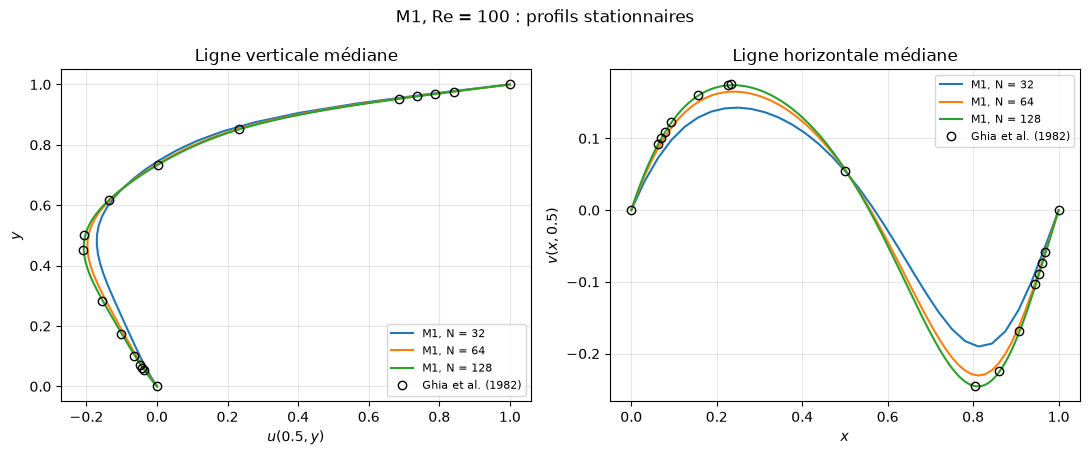

N =  32   max|u - u_Ghia| = 0.0421   max|v - v_Ghia| = 0.0570   min u(0.5, y) = -0.17041 en y = 0.4688   min v(x, 0.5) = -0.19019
N =  64   max|u - u_Ghia| = 0.0141   max|v - v_Ghia| = 0.0156   min u(0.5, y) = -0.19709 en y = 0.4688   min v(x, 0.5) = -0.23059
N = 128   max|u - u_Ghia| = 0.0041   max|v - v_Ghia| = 0.0035   min u(0.5, y) = -0.20756 en y = 0.4609   min v(x, 0.5) = -0.24576


In [8]:
runs = {n: get_run(n, EPS) for n in GRIDS}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for n, r in runs.items():
    u_c, v_c = centerlines(r)
    axes[0].plot(u_c, r["y"], label=f"M1, N = {n}")
    axes[1].plot(r["x"], v_c, label=f"M1, N = {n}")
axes[0].plot(u_ghia, y_ghia, "ko", mfc="none", label="Ghia et al. (1982)")
axes[1].plot(x_ghia, v_ghia, "ko", mfc="none", label="Ghia et al. (1982)")
axes[0].set_xlabel("$u(0.5, y)$"); axes[0].set_ylabel("$y$")
axes[1].set_xlabel("$x$"); axes[1].set_ylabel("$v(x, 0.5)$")
axes[0].set_title("Ligne verticale médiane"); axes[1].set_title("Ligne horizontale médiane")
for ax in axes:
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
fig.suptitle(f"M1, Re = {RE} : profils stationnaires")
fig.tight_layout()
fig.savefig(FIG / "A_M1_profiles.png", dpi=150)
plt.show()

for n, r in runs.items():
    eu, ev = ghia_errors(r)
    u_c, v_c = centerlines(r)
    print(f"N = {n:3d}   max|u - u_Ghia| = {eu:.4f}   max|v - v_Ghia| = {ev:.4f}   "
          f"min u(0.5, y) = {u_c.min():.5f} en y = {r['y'][np.argmin(u_c)]:.4f}   min v(x, 0.5) = {v_c.min():.5f}")

**Lecture.** Les trois grilles convergent vers les points de Ghia ; à $N = 128$, les courbes passent sur les points
(écart max $4.1\cdot10^{-3}$ en $u$ et $3.5\cdot10^{-3}$ en $v$, soit ~2 % et ~1.4 % des extrema $u_\min \approx -0.21$ et
$v_\min \approx -0.245$). $N = 32$ est nettement trop grossier : il sous-estime les extrema (minimum de $v$ : $-0.190$ contre
$-0.245$ chez Ghia). Le minimum de $u$ sur nos nœuds vaut $-0.2076$ en $y = 0.461$ à $N = 128$, contre $-0.2109$ en
$y = 0.453$ chez Ghia.

### 2.d Justification de la grille : deux courbes de convergence

**Ce qu'on fait** (PLAN.md, étape 2) :
1. écart max à Ghia en fonction de $h$ (log-log) ;
2. écart entre grilles successives $\max|u_N - u_{2N}|$ (et de même pour $v$), sur les nœuds communs des lignes
   médianes : il ne dépend d'aucune référence, sa pente donne **notre** ordre observé.

**Ce qu'on attend.** Schéma d'ordre 2 en espace ⇒ pente $\approx 2$. Trois raisons possibles d'une pente plus faible :
la Neumann d'ordre 1 sur $p$ (cf. ADR 0002, à trancher avec M2 à l'étape 3), les singularités des coins du
couvercle (touchent M1 et M2), et pour la courbe 1, l'erreur propre de Ghia (palier possible).
Avec 3 grilles, la courbe 1 donne 2 pentes locales et la courbe 2 une seule.

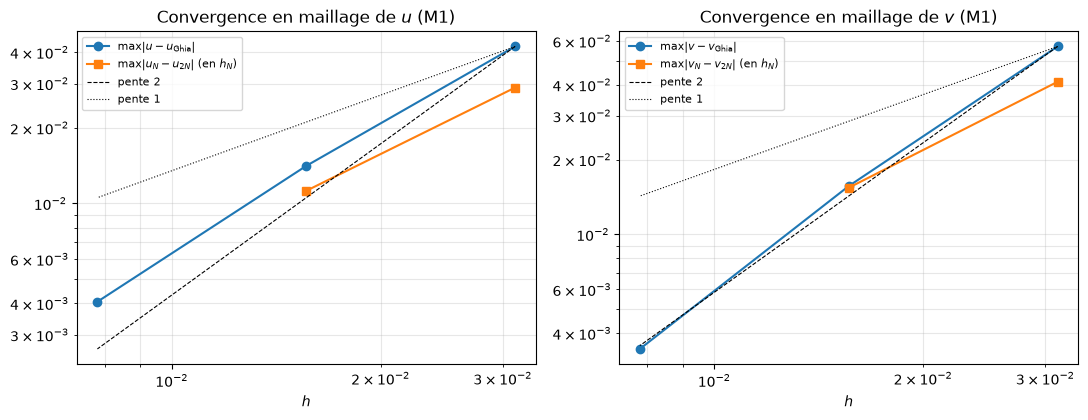

u : écart à Ghia = [0.04214 0.0141  0.00406]  pentes locales [1.58 1.8 ]  (globale 1.69)
    écart grilles successives = [0.02891 0.01122]  pente 1.37
v : écart à Ghia = [0.05703 0.01564 0.00346]  pentes locales [1.87 2.18]  (globale 2.02)
    écart grilles successives = [0.04111 0.0154 ]  pente 1.42


In [9]:
h_list = np.array([runs[n]["h"] for n in GRIDS])
err_ghia = np.array([ghia_errors(runs[n]) for n in GRIDS])        # colonnes : u, v

# Écart entre grilles successives sur les nœuds communs (un nœud sur deux de la grille fine)
diff_succ = []
for n in GRIDS[:-1]:
    u_c, v_c = centerlines(runs[n])
    u_f, v_f = centerlines(runs[2 * n])
    diff_succ.append((np.abs(u_c - u_f[::2]).max(), np.abs(v_c - v_f[::2]).max()))
diff_succ = np.array(diff_succ)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for k, name in enumerate(("u", "v")):
    ax = axes[k]
    ax.loglog(h_list, err_ghia[:, k], "o-", label=rf"$\max|{name} - {name}_\mathrm{{Ghia}}|$")
    ax.loglog(h_list[:-1], diff_succ[:, k], "s-", label=rf"$\max|{name}_N - {name}_{{2N}}|$ (en $h_N$)")
    ref = err_ghia[0, k]
    ax.loglog(h_list, ref * (h_list / h_list[0])**2, "k--", lw=0.8, label="pente 2")
    ax.loglog(h_list, ref * (h_list / h_list[0])**1, "k:", lw=0.8, label="pente 1")
    ax.set_xlabel("$h$"); ax.set_title(f"Convergence en maillage de ${name}$ (M1)")
    ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "A_M1_grid_convergence.png", dpi=150)
plt.show()

for k, name in enumerate(("u", "v")):
    local, glob = observed_slopes(GRIDS, err_ghia[:, k])
    succ_slope = np.log2(diff_succ[0, k] / diff_succ[1, k])
    print(f"{name} : écart à Ghia = {np.round(err_ghia[:, k], 5)}  pentes locales {np.round(local, 2)}"
          f"  (globale {glob:.2f})")
    print(f"    écart grilles successives = {np.round(diff_succ[:, k], 5)}  pente {succ_slope:.2f}")

**Lecture.**
- **Écart entre grilles successives** (indépendant de Ghia) : pente **≈ 1.4** pour $u$ comme pour $v$. C'est notre ordre
  observé : entre 1 et 2, donc inférieur à l'ordre 2 du schéma intérieur.
- **Écart à Ghia** : pentes plus fortes (1.6–1.8 en $u$, 1.9–2.2 en $v$). Les deux courbes ne racontent pas la même chose,
  et c'est attendu : Ghia a sa propre erreur ($129^2$, ordre 2). Si nos solutions convergeaient vers la vraie solution
  avec une pente 1.4, l'erreur restante de $N = 128$ serait d'environ $0.011/(2^{1.4}-1) \approx 7\cdot10^{-3}$ en $u$, plus que
  notre écart à Ghia ($4\cdot10^{-3}$) : Ghia, à une résolution voisine de la nôtre, est vraisemblablement écarté de la vraie
  solution dans le même sens que nous. L'écart à Ghia surestime donc notre ordre ; on retient l'écart entre grilles.
- **Pourquoi pas 2 ?** Deux suspects (PLAN.md, étape 2) : la Neumann d'ordre 1 sur $p$ (ADR 0002) et les singularités des
  coins. On ne tranche pas ici : c'est le rôle de la comparaison avec M2 (étape 3), qui n'a pas de Neumann.
- **Choix de la grille** : à $N = 128$, l'écart à Ghia (~2 % de $|u_\min|$) est du même ordre que l'incertitude de Ghia
  lui-même ; passer à $N = 256$ coûterait ~30 fois plus pour un gain qu'on ne pourrait pas vérifier contre Ghia.
  **On retient $N = 128$** pour la suite (sous réserve de l'étape 3).

### 2.e $K(t)$ et $P(t)$, et décroissance du résidu

**Ce qu'on fait.** Les deux diagnostics de l'énoncé, à chaque pas de temps, pour les trois grilles. À droite, le résidu
stationnaire $\|R\|$ (échelle log), avec $t_\text{ref}$ et le seuil d'arrêt $\varepsilon\|R(t_\text{ref})\|$ de chaque grille.

**Ce qu'on attend.** $K$ et $P$ montent avec la rampe du couvercle (temps caractéristique 1), puis tendent vers un
palier. $K$ devrait converger avec $N$ (grandeur intégrale, régulière) ; $P$ devrait **croître** avec $N$
(singularité des coins). Le résidu devrait décroître exponentiellement, avec la même pente sur les trois grilles
(le taux d'amortissement $\lambda$ est une propriété de l'écoulement).

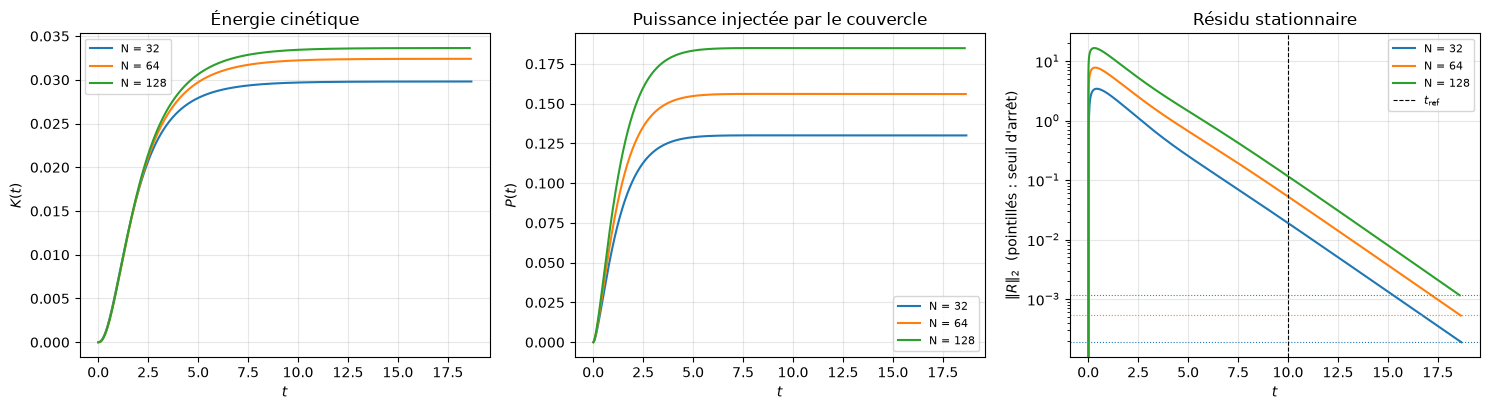

N =  32   arrêt à t = 18.67   λ = 0.532   K_final = 0.029808   P_final = 0.129987
N =  64   arrêt à t = 18.65   λ = 0.533   K_final = 0.032402   P_final = 0.156004
N = 128   arrêt à t = 18.59   λ = 0.536   K_final = 0.033633   P_final = 0.184837


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for n, r in runs.items():
    axes[0].plot(r["t"], r["K"], label=f"N = {n}")
    axes[1].plot(r["t"], r["P"], label=f"N = {n}")
    line, = axes[2].semilogy(r["t"], r["residual"], label=f"N = {n}")
    axes[2].axhline(EPS * r["residual_ref"], color=line.get_color(), ls=":", lw=0.8)
axes[2].axvline(T_REF, color="k", ls="--", lw=0.8, label=r"$t_\mathrm{ref}$")
axes[0].set_ylabel("$K(t)$"); axes[1].set_ylabel("$P(t)$")
axes[2].set_ylabel(r"$\|R\|_2$  (pointillés : seuil d'arrêt)")
for ax in axes:
    ax.set_xlabel("$t$"); ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
axes[0].set_title("Énergie cinétique"); axes[1].set_title("Puissance injectée par le couvercle")
axes[2].set_title("Résidu stationnaire")
fig.tight_layout()
fig.savefig(FIG / "A_M1_K_P.png", dpi=150)
plt.show()

# Taux d'amortissement λ : pente de ln||R|| après t_ref (régression écrite à la main, cf. observed_slopes)
for n, r in runs.items():
    after = r["t"] >= T_REF
    tt, lr = r["t"][after], np.log(r["residual"][after])
    lam = -np.sum((tt - tt.mean()) * (lr - lr.mean())) / np.sum((tt - tt.mean())**2)
    print(f"N = {n:3d}   arrêt à t = {r['t_final']:.2f}   λ = {lam:.3f}   "
          f"K_final = {r['K'][-1]:.6f}   P_final = {r['P'][-1]:.6f}")

**Lecture.**
- $K$ et $P$ suivent la rampe du couvercle puis atteignent un palier vers $t \approx 6$–$8$, sans dépassement : à $Re = 100$, le
  régime transitoire est un simple amortissement visqueux.
- **$K$ converge** : 0.02981, 0.03240, 0.03363 ; les accroissements diminuent ($2.6\cdot10^{-3}$ puis $1.2\cdot10^{-3}$, rapport 2.1,
  donc ordre ≈ 1 sur $K$). C'est une grandeur intégrale régulière, utilisable pour juger la grille.
- **$P$ ne converge pas** : 0.130, 0.156, 0.185 (voir 2.f).
- **Résidu** : décroissance exponentielle après le transitoire, avec **le même taux sur les trois grilles**,
  $\lambda \approx 0.53$ : c'est le taux d'amortissement du mode le plus lent, une propriété de l'écoulement et non de la grille.
  Les résidus des trois grilles ne sont pas égaux (le résidu L2 somme sur plus de nœuds quand $N$ grandit), mais le critère
  étant un **rapport** à $\|R(t_\text{ref})\|$, ils s'arrêtent au même instant.

### 2.f $P$ stationnaire en fonction de $\ln N$

**Ce qu'on fait.** On trace $P_\text{final}$ contre $\ln N$ et on ajuste $P = a + c\ln N$ (régression sur 3 points).

**Ce qu'on attend** (PLAN.md §2, « Singularités aux coins du couvercle ») : aux deux coins, la vitesse de paroi saute
de $U_t$ à 0, $\partial_y u \sim 1/r$, donc $\int \nu\,\partial_y u\,dx$ diverge comme $\ln$ en continu. La grille coupe à $r \approx h$ :
$P \approx P_\text{régulier} + c\,\nu\ln N$. On attend donc **une droite, sans palier** : $P$ ne converge pas en maillage
et ne peut pas servir à choisir $N$. Le choix de $N$ se fait sur les profils (2.d) et sur $K$.

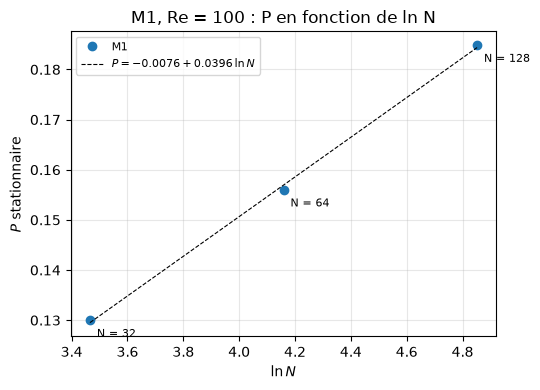

P_final : [0.129987 0.156004 0.184837]   accroissements : [0.026017 0.028833]
pente c = 0.03957   c / ν = 3.957
K_final : [0.029808 0.032402 0.033633]   accroissements : [0.002594 0.001231]


In [11]:
n_arr = np.array(GRIDS, dtype=float)
p_final = np.array([runs[n]["P"][-1] for n in GRIDS])
k_final = np.array([runs[n]["K"][-1] for n in GRIDS])
ln_n = np.log(n_arr)
c_fit = np.sum((ln_n - ln_n.mean()) * (p_final - p_final.mean())) / np.sum((ln_n - ln_n.mean())**2)
a_fit = p_final.mean() - c_fit * ln_n.mean()

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(ln_n, p_final, "o", label="M1")
ax.plot(ln_n, a_fit + c_fit * ln_n, "k--", lw=0.8, label=rf"$P = {a_fit:.4f} + {c_fit:.4f}\,\ln N$")
for n, lp, pp in zip(GRIDS, ln_n, p_final):
    ax.annotate(f"N = {n}", (lp, pp), textcoords="offset points", xytext=(5, -12), fontsize=8)
ax.set_xlabel(r"$\ln N$"); ax.set_ylabel(r"$P$ stationnaire")
ax.set_title(f"M1, Re = {RE} : P en fonction de ln N")
ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "A_M1_P_lnN.png", dpi=150)
plt.show()

print("P_final :", np.round(p_final, 6), "  accroissements :", np.round(np.diff(p_final), 6))
print(f"pente c = {c_fit:.5f}   c / ν = {c_fit / NU:.3f}")
print("K_final :", np.round(k_final, 6), "  accroissements :", np.round(np.diff(k_final), 6))

**Lecture.** $P$ augmente de **0.026 puis 0.029** à chaque doublement de $N$ : les trois points sont presque alignés en $\ln N$,
sans palier, comme attendu pour la singularité des coins ($P \approx a + c\ln N$, $c \approx 0.040 \approx 4\nu$). Les accroissements
croissent légèrement (+11 %) : la partie régulière de $P$ converge aussi (à l'ordre ~1 comme $K$), ce qui s'ajoute à la
croissance logarithmique ; 3 points ne permettent pas de séparer les deux.
**Conséquence** : $P$ ne sert pas à choisir $N$ ; dans les Parties B et C, on comparera toujours les $P$ **à $N$ fixé**.

### 2.g Effet de la tolérance du gradient conjugué (workshop 15)

**Ce qu'on fait** (ADR 0003 §3) : on refait $N = 128$, la grille la plus exigeante, avec tol $= 10^{-10}$ au lieu de $10^{-8}$
(même $\varepsilon$), et on compare les profils.

**Ce qu'on attend.** Si l'écart entre les deux calculs est très petit devant l'écart à Ghia, une tolérance fixe de
$10^{-8}$ suffit pour toutes nos grilles. Le calcul coûte plus cher (plus d'itérations par pas).

In [12]:
compute_missing([(128, 1e-10, EPS)])
r8 = runs[128]
r10 = get_run(128, EPS, cg_tol=1e-10)
u8, v8 = centerlines(r8)
u10, v10 = centerlines(r10)
eu8, ev8 = ghia_errors(r8)
print(f"tol 1e-8  : it. GC moy = {r8['cg_iterations'].mean():6.1f}   t_final = {r8['t_final']:.2f}")
print(f"tol 1e-10 : it. GC moy = {r10['cg_iterations'].mean():6.1f}   t_final = {r10['t_final']:.2f}")
print(f"max|u(1e-8) - u(1e-10)| = {np.abs(u8 - u10).max():.2e}   (écart à Ghia : {eu8:.2e})")
print(f"max|v(1e-8) - v(1e-10)| = {np.abs(v8 - v10).max():.2e}   (écart à Ghia : {ev8:.2e})")
print(f"P : {r8['P'][-1]:.6f} (1e-8)  vs  {r10['P'][-1]:.6f} (1e-10)")

tol 1e-8  : it. GC moy =  188.1   t_final = 18.59
tol 1e-10 : it. GC moy =  346.5   t_final = 18.59
max|u(1e-8) - u(1e-10)| = 6.39e-11   (écart à Ghia : 4.06e-03)
max|v(1e-8) - v(1e-10)| = 9.79e-11   (écart à Ghia : 3.46e-03)
P : 0.184837 (1e-8)  vs  0.184837 (1e-10)


**Lecture.** Passer de tol $= 10^{-8}$ à $10^{-10}$ change les profils de $\sim 10^{-10}$, soit **sept ordres de grandeur sous**
l'écart à Ghia, et ne change pas $P$. La borne de l'ADR 0003 ($\sim 7\cdot10^{-5}$) était très pessimiste. **tol $= 10^{-8}$ suffit**
pour toutes nos grilles ; la diminuer presque doublerait le nombre d'itérations du gradient conjugué, pour rien.

### 2.h Récapitulatif M1 (sauvegardé dans `results/A_M1_summary.csv`)

Temps de calcul de référence : mesurés en 2.a pendant que 9 calculs tournaient en parallèle. Pour mémoire, le
portage Numba a été vérifié contre l'ancienne version numpy pure (`results/ref_numpy/`, ancien critère d'arrêt) :
mêmes champs à $2\cdot10^{-10}$ près, et 3 à 5 fois plus rapide (N = 32 : 0.6 s contre 2.9 s ; N = 64 : 5.2 s contre 21.5 s ;
N = 128 : 99 s contre 299 s).

In [13]:
summary = np.array([[n, runs[n]["dt"], runs[n]["n_steps"], runs[n]["t_final"], runs[n]["wall_time"],
                     runs[n]["cg_iterations"].mean(), *ghia_errors(runs[n]),
                     runs[n]["K"][-1], runs[n]["P"][-1]] for n in GRIDS])
np.savetxt(RES / "A_M1_summary.csv", summary, delimiter=",", fmt="%.6e",
           header=f"critere residu eps = {EPS:.0e} (t_ref = {T_REF}), tol GC {CG_TOL:.0e}\n"
                  "N,dt,n_steps,t_final,wall_time_s,cg_iter_mean,err_ghia_u,err_ghia_v,K_final,P_final")
for row in summary:
    print(f"N = {int(row[0]):3d}   calcul = {row[4]:7.1f} s   écart Ghia (u, v) = ({row[6]:.4f}, {row[7]:.4f})"
          f"   K = {row[8]:.5f}   P = {row[9]:.5f}")

N =  32   calcul =     0.9 s   écart Ghia (u, v) = (0.0421, 0.0570)   K = 0.02981   P = 0.12999
N =  64   calcul =     6.7 s   écart Ghia (u, v) = (0.0141, 0.0156)   K = 0.03240   P = 0.15600
N = 128   calcul =   118.2 s   écart Ghia (u, v) = (0.0041, 0.0035)   K = 0.03363   P = 0.18484


**Bilan de l'étape 2 (M1, $Re = 100$).** M1 reproduit Ghia à ~2 % des extrema près à $N = 128$, avec un ordre observé ≈ 1.4
sur les profils (écart entre grilles). $K$ converge, $P$ croît en $\ln N$ (coins). Réglages validés : tol $= 10^{-8}$ ;
critère d'arrêt sur le résidu, $\varepsilon = 10^{-2}$ à partir de $t_\text{ref} = 10$. Grille retenue : $N = 128$. À l'étape 3, M2 dira si
l'ordre ≈ 1.4 vient de la Neumann d'ordre 1 (M1 seul) ou des coins (M1 et M2).

## 3. M2 (fonction de courant / vorticité) et validation croisée M1 / M2

### 3.a Calculs M2

**Ce qu'on fait.** M2 (`cavity/psi_omega.py`, cours §7.3.4) sur la **même grille** et avec les **mêmes briques** que M1
(`cavity/common.py`) : Euler explicite, advection centrée, diffusion centrée, gradient conjugué (ici en Dirichlet pour
$\Delta\psi = -\omega$, tol $= 10^{-8}$, départ à chaud), même $\Delta t$, même critère d'arrêt sur le résidu ($\varepsilon$ retenu en 2.b) et
mêmes diagnostics $K$, $P$. Vorticité de paroi par la formule de Thom (Taylor sur $\psi$, cf. `docs/pseudocode.md`).
$N = 32, 64, 128$, en parallèle.

**Ce qu'on attend.** Un écoulement stationnaire proche de celui de M1 et de Ghia. M2 n'a **pas de pression**, donc pas de
condition de Neumann : si la Neumann d'ordre 1 de M1 limite sa précision (ADR 0002), M2 devrait être plus précis et
converger plus vite. Coût par pas comparable (un Poisson par pas dans les deux cas).

In [14]:
compute_missing([(n, CG_TOL, EPS) for n in GRIDS], method="M2")
runs2 = {n: get_run(n, EPS, method="M2") for n in GRIDS}

print(f"{'N':>4} {'dt':>9} {'pas':>6} {'t_final':>7} {'M2 (s)':>8} {'M1 (s)':>8} {'it. GC M2':>9} {'it. GC M1':>9} {'arrêt':>8}")
for n in GRIDS:
    r2, r1 = runs2[n], runs[n]
    stop = "critère" if r2["converged"] else "t_max !"
    print(f"{n:4d} {r2['dt']:9.3e} {r2['n_steps']:6d} {r2['t_final']:7.2f} {r2['wall_time']:8.1f} "
          f"{r1['wall_time']:8.1f} {r2['cg_iterations'].mean():9.1f} {r1['cg_iterations'].mean():9.1f} {stop:>8}")
print("(temps mesurés avec plusieurs calculs en parallèle)")

   N        dt    pas t_final   M2 (s)   M1 (s) it. GC M2 it. GC M1    arrêt
  32 1.250e-02   1491   18.64      0.5      0.9      59.1      76.1  critère
  64 4.883e-03   3803   18.57      3.6      6.7     113.0     134.3  critère
 128 1.221e-03  15201   18.56     83.4    118.2     205.5     188.1  critère
(temps mesurés avec plusieurs calculs en parallèle)


**Lecture.** M2 devient stationnaire sur les trois grilles, au même instant que M1 ($t \approx 18.6$ : même critère, même
taux d'amortissement, c'est bien le même écoulement). Il est un peu moins cher que M1 (un Poisson par pas dans les deux
cas, mais un seul champ transporté, $\omega$, au lieu de $u$ et $v$, et pas de divergence ni de gradient de pression).

### 3.b M1, M2 et Ghia sur la même figure

**Ce qu'on fait.** Profils $u(0.5, y)$ et $v(x, 0.5)$ à $N = 128$ (grille retenue) pour M1 et M2, avec les points de Ghia ;
en dessous, l'écart M1 − M2 le long des deux lignes médianes, pour les trois grilles.

**Ce qu'on attend.** Les deux méthodes et Ghia superposés à l'échelle du tracé. L'écart M1 − M2 doit diminuer quand $N$
augmente (les deux méthodes discrétisent le même problème continu) ; sa forme indique où les méthodes diffèrent.

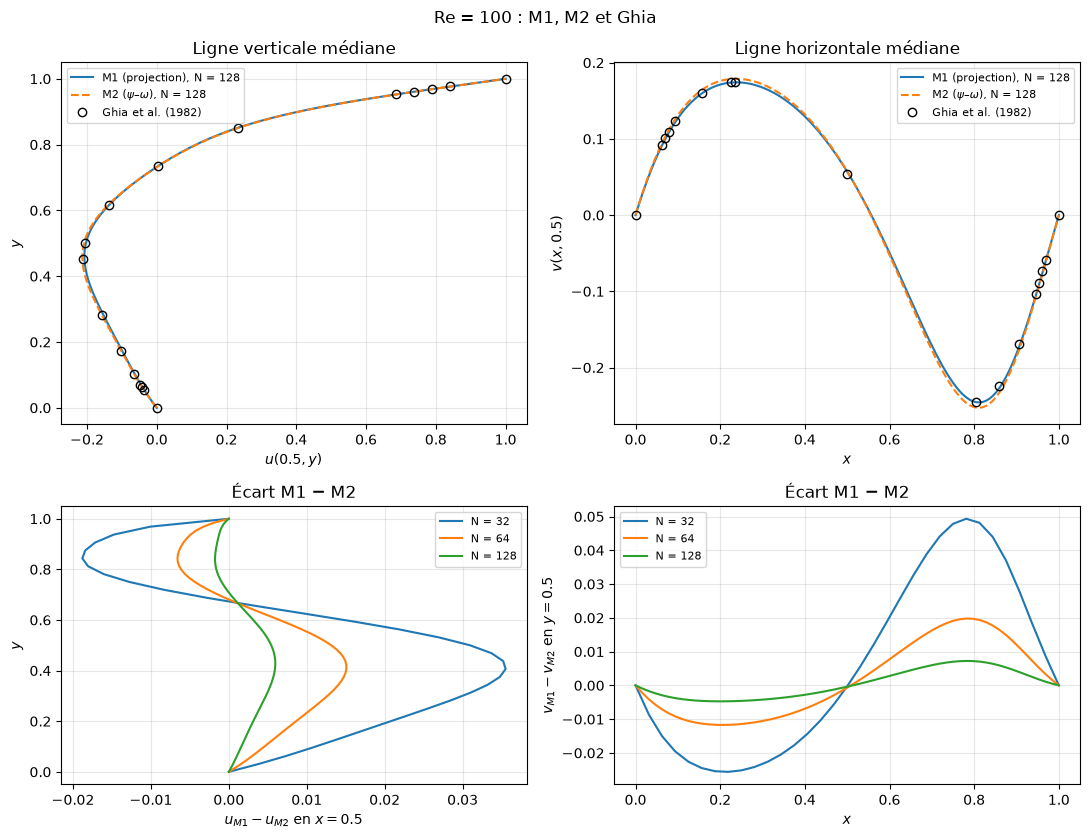

N =  32   max|M1 - M2| : u 0.0355, v 0.0493   |   écart à Ghia  M1 : u 0.0421, v 0.0570   M2 : u 0.0089, v 0.0086
N =  64   max|M1 - M2| : u 0.0151, v 0.0198   |   écart à Ghia  M1 : u 0.0141, v 0.0156   M2 : u 0.0026, v 0.0059
N = 128   max|M1 - M2| : u 0.0060, v 0.0072   |   écart à Ghia  M1 : u 0.0041, v 0.0035   M2 : u 0.0042, v 0.0084
pente de max|M1 - M2| en u : locales [1.24 1.34]  (globale 1.29)
pente de max|M1 - M2| en v : locales [1.32 1.45]  (globale 1.38)


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), gridspec_kw={"height_ratios": [1.3, 1]})
u1, v1 = centerlines(runs[128])
u2, v2 = centerlines(runs2[128])
x128, y128 = runs[128]["x"], runs[128]["y"]
axes[0, 0].plot(u1, y128, label="M1 (projection), N = 128")
axes[0, 0].plot(u2, y128, "--", label=r"M2 ($\psi$–$\omega$), N = 128")
axes[0, 0].plot(u_ghia, y_ghia, "ko", mfc="none", label="Ghia et al. (1982)")
axes[0, 1].plot(x128, v1, label="M1 (projection), N = 128")
axes[0, 1].plot(x128, v2, "--", label=r"M2 ($\psi$–$\omega$), N = 128")
axes[0, 1].plot(x_ghia, v_ghia, "ko", mfc="none", label="Ghia et al. (1982)")
axes[0, 0].set_xlabel("$u(0.5, y)$"); axes[0, 0].set_ylabel("$y$")
axes[0, 1].set_xlabel("$x$"); axes[0, 1].set_ylabel("$v(x, 0.5)$")
axes[0, 0].set_title("Ligne verticale médiane"); axes[0, 1].set_title("Ligne horizontale médiane")

for n in GRIDS:
    a1, b1 = centerlines(runs[n])
    a2, b2 = centerlines(runs2[n])
    axes[1, 0].plot(a1 - a2, runs[n]["y"], label=f"N = {n}")
    axes[1, 1].plot(runs[n]["x"], b1 - b2, label=f"N = {n}")
axes[1, 0].set_xlabel(r"$u_{M1} - u_{M2}$ en $x = 0.5$"); axes[1, 0].set_ylabel("$y$")
axes[1, 1].set_xlabel("$x$"); axes[1, 1].set_ylabel(r"$v_{M1} - v_{M2}$ en $y = 0.5$")
axes[1, 0].set_title("Écart M1 − M2"); axes[1, 1].set_title("Écart M1 − M2")
for ax in axes.ravel():
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
fig.suptitle(f"Re = {RE} : M1, M2 et Ghia")
fig.tight_layout()
fig.savefig(FIG / "A_M1_M2_Ghia.png", dpi=150)
plt.show()

diff_m1m2 = np.array([[np.abs(centerlines(runs[n])[k] - centerlines(runs2[n])[k]).max() for k in (0, 1)]
                      for n in GRIDS])
for n, (du, dv) in zip(GRIDS, diff_m1m2):
    eu1, ev1 = ghia_errors(runs[n])
    eu2, ev2 = ghia_errors(runs2[n])
    print(f"N = {n:3d}   max|M1 - M2| : u {du:.4f}, v {dv:.4f}   |   écart à Ghia  M1 : u {eu1:.4f}, v {ev1:.4f}"
          f"   M2 : u {eu2:.4f}, v {ev2:.4f}")
for k, name in enumerate(("u", "v")):
    local, glob = observed_slopes(GRIDS, diff_m1m2[:, k])
    print(f"pente de max|M1 - M2| en {name} : locales {np.round(local, 2)}  (globale {glob:.2f})")

**Lecture.**
- À $N = 128$, M1, M2 et Ghia se superposent à l'échelle du tracé sur $u$ ; sur $v$, M2 creuse un peu plus les extrema
  (minimum de $v$ vers $x \approx 0.81$–$0.86$) que M1 et Ghia.
- **L'écart M1 − M2 diminue avec $N$** (0.035 → 0.015 → 0.006 en $u$ ; 0.049 → 0.020 → 0.007 en $v$), avec une pente ≈ 1.3–1.4 :
  les deux méthodes convergent vers **la même solution**, et c'est la plus lente (M1) qui fixe la vitesse de rapprochement.
- La forme de l'écart est la même sur les trois grilles (deux lobes, maxima dans le tourbillon, vers $y \approx 0.4$ et
  $x \approx 0.2$ et $0.8$) : c'est une erreur régulière, étalée sur tout l'écoulement, comme celle de la pression Neumann en §1.c,
  pas une erreur localisée aux coins.

### 3.c Convergence en maillage de M2, comparée à M1 — lecture des pentes

**Ce qu'on fait.** Les deux mêmes courbes qu'en 2.d (écart à Ghia ; écart entre grilles successives), pour M2, tracées avec
celles de M1. Lecture prévue par PLAN.md (étape 2) et l'ADR 0002 :
- pente faible pour **M1 et M2** ⇒ suspect = **singularités des coins** (elles touchent les deux méthodes) ;
- pente faible pour **M1 seulement** (≈ 1–1.5 pour M1, ≈ 2 pour M2) ⇒ suspect = **Neumann d'ordre 1 sur $p$** (propre à M1).

**Ce qu'on attend.** Rien n'est tranché d'avance ; on a seulement mesuré que le Poisson Neumann seul est d'ordre 1 (§1.c).

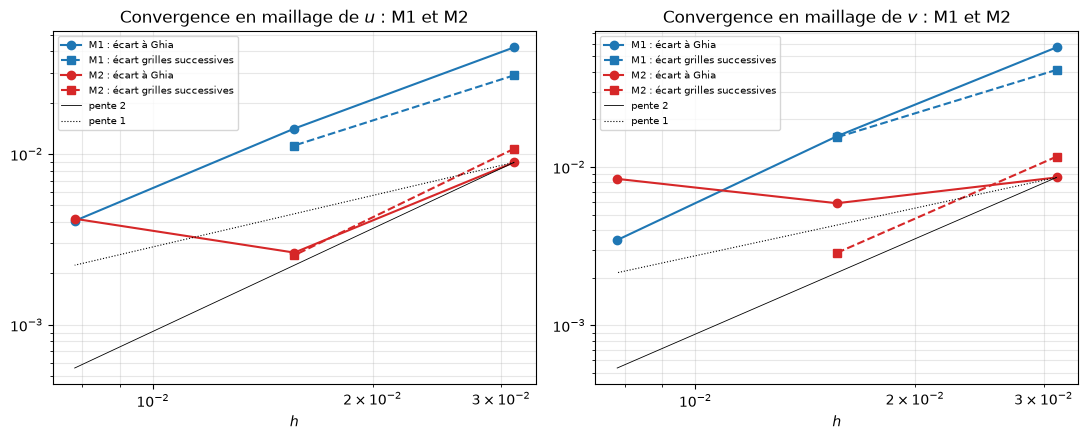

                                                M1                     M2
   u    pentes écart à Ghia            [1.58 1.8 ]          [ 1.75 -0.66]
        pente grilles succ.                   1.37                   2.07
       écarts grilles succ.      [0.02891 0.01122]      [0.01074 0.00255]
   v    pentes écart à Ghia            [1.87 2.18]          [ 0.54 -0.51]
        pente grilles succ.                   1.42                   2.02
       écarts grilles succ.      [0.04111 0.0154 ]      [0.01163 0.00287]


In [16]:
err_ghia2 = np.array([ghia_errors(runs2[n]) for n in GRIDS])
diff_succ2 = []
for n in GRIDS[:-1]:
    u_c, v_c = centerlines(runs2[n])
    u_f, v_f = centerlines(runs2[2 * n])
    diff_succ2.append((np.abs(u_c - u_f[::2]).max(), np.abs(v_c - v_f[::2]).max()))
diff_succ2 = np.array(diff_succ2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for k, name in enumerate(("u", "v")):
    ax = axes[k]
    ax.loglog(h_list, err_ghia[:, k], "o-", color="C0", label=f"M1 : écart à Ghia")
    ax.loglog(h_list[:-1], diff_succ[:, k], "s--", color="C0", label=f"M1 : écart grilles successives")
    ax.loglog(h_list, err_ghia2[:, k], "o-", color="C3", label=f"M2 : écart à Ghia")
    ax.loglog(h_list[:-1], diff_succ2[:, k], "s--", color="C3", label=f"M2 : écart grilles successives")
    ref = err_ghia2[0, k]
    ax.loglog(h_list, ref * (h_list / h_list[0])**2, "k-", lw=0.6, label="pente 2")
    ax.loglog(h_list, ref * (h_list / h_list[0])**1, "k:", lw=0.8, label="pente 1")
    ax.set_xlabel("$h$"); ax.set_title(f"Convergence en maillage de ${name}$ : M1 et M2")
    ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG / "A_M1_M2_grid_convergence.png", dpi=150)
plt.show()

print(f"{'':>4} {'':>22} {'M1':>22} {'M2':>22}")
for k, name in enumerate(("u", "v")):
    l1, g1 = observed_slopes(GRIDS, err_ghia[:, k])
    l2, g2 = observed_slopes(GRIDS, err_ghia2[:, k])
    s1 = np.log2(diff_succ[0, k] / diff_succ[1, k])
    s2 = np.log2(diff_succ2[0, k] / diff_succ2[1, k])
    print(f"{name:>4} {'pentes écart à Ghia':>22} {str(np.round(l1, 2)):>22} {str(np.round(l2, 2)):>22}")
    print(f"{'':>4} {'pente grilles succ.':>22} {s1:22.2f} {s2:22.2f}")
    print(f"{'':>4} {'écarts grilles succ.':>22} {str(np.round(diff_succ[:, k], 5)):>22} {str(np.round(diff_succ2[:, k], 5)):>22}")

**Lecture.**
- **Écart entre grilles successives** (indépendant de Ghia) : **M2 ≈ 2.0** ($u$ : 2.07, $v$ : 2.02), **M1 ≈ 1.4**. M2 atteint l'ordre 2
  de ses schémas malgré les singularités des coins et malgré Thom (d'ordre 1 localement, mais l'ordre 2 global est préservé,
  comme l'annonce Erturk et al.). **Les coins ne limitent donc pas l'ordre sur les profils**.
- **Grille de lecture du PLAN** : pente faible pour **M1 seulement** ⇒ premier suspect = **Neumann d'ordre 1 sur $p$**, la seule
  brique que M1 a et que M2 n'a pas (cf. §1.c : le Poisson Neumann seul est d'ordre 1). La pente de M1 (1.4, entre 1 et 2)
  est compatible avec une erreur d'ordre 1 qui n'est pas encore dominante sur toutes les grilles.
- **Écart à Ghia de M2** : il **ne diminue plus** entre $N = 64$ et $128$ (0.0026 → 0.0042 en $u$, 0.0059 → 0.0084 en $v$), alors
  que M2 converge à l'ordre 2 (son $N = 128$ est à environ $0.003/3 \approx 10^{-3}$ de sa limite). C'est le palier annoncé par le PLAN :
  à partir de là, l'écart à Ghia mesure surtout **l'erreur de Ghia** (129×129, ordre 2), de l'ordre de $4$–$8\cdot10^{-3}$ sur nos
  lignes médianes, pire sur le minimum de $v$ (M2 le donne environ 3 % plus creusé). On ne peut pas trancher plus avec
  Ghia seul ; la cohérence M1 → M2 (l'écart diminue) va dans ce sens.
- Conséquence pour M1 : son bon accord avec Ghia à $N = 128$ est en partie **fortuit** — M1, encore loin de sa limite, se
  rapproche de M2 en passant par les valeurs de Ghia. C'est pourquoi on juge l'ordre sur l'écart entre grilles, pas sur Ghia.
- **Décision à prendre** (ADR 0002, PLAN « signal à surveiller ») : la condition « M1 faible, M2 ≈ 2 » est remplie ; l'option
  prévue est la Neumann d'ordre 2 par nœuds fantômes (miroir pair, lignes de bord pondérées pour garder le gradient conjugué).

### 3.d $K$ et $P$ : M1 et M2

**Ce qu'on fait.** Valeurs stationnaires de $K$ et $P$ des deux méthodes sur les trois grilles, et $P$ en fonction de $\ln N$.

**Ce qu'on attend.** $K$ des deux méthodes vers une même limite. $P$ croissant en $\ln N$ pour les deux (singularité des coins,
propriété du problème et non de la méthode) ; les pentes $c$ peuvent différer un peu (les deux méthodes ne traitent pas
le voisinage du coin de la même façon : vitesse tirée de $\psi$ pour M2).

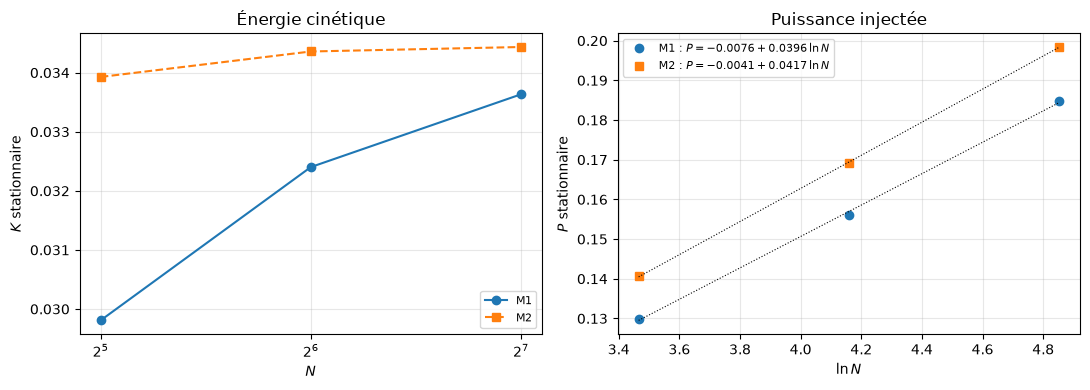

K M1 : [0.029808 0.032402 0.033633]  accroissements [0.002594 0.001231]
K M2 : [0.033927 0.034358 0.034434]  accroissements [4.31e-04 7.60e-05]
P M1 : [0.129987 0.156004 0.184837]  accroissements [0.026017 0.028833]
P M2 : [0.140579 0.169197 0.198399]  accroissements [0.028617 0.029203]
pentes c : M1 0.03957 (3.96 ν),  M2 0.04171 (4.17 ν)


In [17]:
k1 = np.array([runs[n]["K"][-1] for n in GRIDS]);  k2 = np.array([runs2[n]["K"][-1] for n in GRIDS])
p1 = np.array([runs[n]["P"][-1] for n in GRIDS]);  p2 = np.array([runs2[n]["P"][-1] for n in GRIDS])


def fit_ln(values):
    # P = a + c ln N, régression écrite à la main (comme en 2.f)
    c = np.sum((ln_n - ln_n.mean()) * (values - values.mean())) / np.sum((ln_n - ln_n.mean())**2)
    return values.mean() - c * ln_n.mean(), c


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(GRIDS, k1, "o-", label="M1"); axes[0].plot(GRIDS, k2, "s--", label="M2")
axes[0].set_xscale("log", base=2); axes[0].set_xlabel("$N$"); axes[0].set_ylabel("$K$ stationnaire")
axes[0].set_title("Énergie cinétique")
for vals, mk, lab in ((p1, "o", "M1"), (p2, "s", "M2")):
    a, c = fit_ln(vals)
    axes[1].plot(ln_n, vals, mk, label=f"{lab} : $P = {a:.4f} + {c:.4f}\\,\\ln N$")
    axes[1].plot(ln_n, a + c * ln_n, "k:", lw=0.8)
axes[1].set_xlabel(r"$\ln N$"); axes[1].set_ylabel("$P$ stationnaire"); axes[1].set_title("Puissance injectée")
for ax in axes:
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "A_M1_M2_K_P.png", dpi=150)
plt.show()

for name, a_, b_ in (("K", k1, k2), ("P", p1, p2)):
    print(f"{name} M1 : {np.round(a_, 6)}  accroissements {np.round(np.diff(a_), 6)}")
    print(f"{name} M2 : {np.round(b_, 6)}  accroissements {np.round(np.diff(b_), 6)}")
print(f"pentes c : M1 {fit_ln(p1)[1]:.5f} ({fit_ln(p1)[1] / NU:.2f} ν),  M2 {fit_ln(p2)[1]:.5f} ({fit_ln(p2)[1] / NU:.2f} ν)")

**Lecture.**
- **$K$** : M2 converge très vite (accroissements $4.3\cdot10^{-4}$ puis $7.6\cdot10^{-5}$, rapport 5.7, ordre ≈ 2.5) vers $K \approx 0.0344$–$0.0345$ ;
  M1 s'en approche lentement (rapport 2.1, ordre ≈ 1). Même lecture que sur les profils : M1 et M2 vont vers la même limite,
  M1 plus lentement.
- **$P$** : les deux méthodes croissent en $\ln N$, avec des pentes voisines ($c \approx 4.0\nu$ pour M1, $4.2\nu$ pour M2), et des
  accroissements presque constants pour M2 (0.0286 puis 0.0292). La croissance en $\ln N$ est donc bien une propriété du
  problème (singularité des coins), pas d'une méthode. Les valeurs de $P$ diffèrent d'environ 0.014 à $N$ fixé : on ne
  comparera les $P$ qu'à $N$ **et** méthode fixés.

### 3.e Récapitulatif M1 / M2 (sauvegardé dans `results/A_M1_M2_summary.csv`)

In [18]:
rows = []
for n in GRIDS:
    for tag, rr in (("M1", runs[n]), ("M2", runs2[n])):
        rows.append([n, 1 if tag == "M1" else 2, rr["wall_time"], rr["cg_iterations"].mean(),
                     *ghia_errors(rr), rr["K"][-1], rr["P"][-1]])
np.savetxt(RES / "A_M1_M2_summary.csv", np.array(rows), delimiter=",", fmt="%.6e",
           header=f"Re = {RE}, critere residu eps = {EPS:.0e} (t_ref = {T_REF}), tol GC {CG_TOL:.0e}\n"
                  "N,methode(1=M1 projection, 2=M2 psi-omega),wall_time_s,cg_iter_mean,err_ghia_u,err_ghia_v,K_final,P_final")
for row in rows:
    print(f"N = {int(row[0]):3d}  M{int(row[1])}   calcul = {row[2]:6.1f} s   écart Ghia (u, v) = ({row[4]:.4f}, {row[5]:.4f})"
          f"   K = {row[6]:.5f}   P = {row[7]:.5f}")

N =  32  M1   calcul =    0.9 s   écart Ghia (u, v) = (0.0421, 0.0570)   K = 0.02981   P = 0.12999
N =  32  M2   calcul =    0.5 s   écart Ghia (u, v) = (0.0089, 0.0086)   K = 0.03393   P = 0.14058
N =  64  M1   calcul =    6.7 s   écart Ghia (u, v) = (0.0141, 0.0156)   K = 0.03240   P = 0.15600
N =  64  M2   calcul =    3.6 s   écart Ghia (u, v) = (0.0026, 0.0059)   K = 0.03436   P = 0.16920
N = 128  M1   calcul =  118.2 s   écart Ghia (u, v) = (0.0041, 0.0035)   K = 0.03363   P = 0.18484
N = 128  M2   calcul =   83.4 s   écart Ghia (u, v) = (0.0042, 0.0084)   K = 0.03443   P = 0.19840


**Bilan de l'étape 3.** M2, avec les mêmes briques que M1, converge à l'ordre 2 et sert de référence indépendante : M1 et M2
vont vers la même solution, M1 plus lentement (ordre ≈ 1.4). Le diagnostic du PLAN désigne la **Neumann d'ordre 1** de M1.
L'écart de M2 à Ghia plafonne vers $4$–$8\cdot10^{-3}$ : vraisemblablement l'erreur propre de Ghia. $P$ croît en $\ln N$ pour les deux
méthodes. Décision ouverte : passer M1 à la Neumann d'ordre 2 (ADR 0002, option 2), ou garder l'ordre 1 et l'expliquer.